# Task vector arithmetic

Combine parameter displacements measured from a common starting point.

A task vector is the difference between a task checkpoint and the shared base. A linear regressor on orthogonal input features gives an example where two independent edits compose exactly. A correlated-feature counterexample shows when both tasks cannot be satisfied simultaneously.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

squared errors for tasks A and B
[[2.25 1.44]
 [0.   1.44]
 [2.25 0.  ]
 [0.   0.  ]]
best shared prediction for conflicting targets 0.0 irreducible mean squared error 1.0


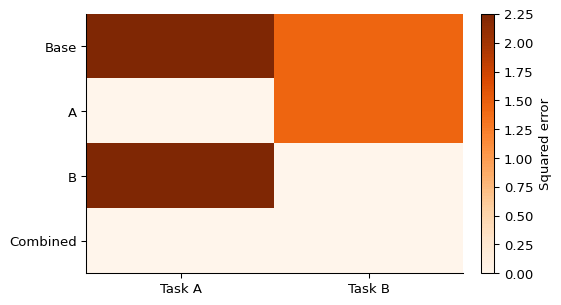

In [2]:
base = np.array([0.5, -0.2])
A = base + [1.5, 0]
B = base + [0, -1.2]
X = np.eye(2)
truth = np.array([A[0], B[1]])
models = np.stack([base, A, B, base + (A - base) + (B - base)])
err = (models @ X.T - truth) ** 2
print("squared errors for tasks A and B")
print(err.round(3))
assert np.allclose(err[-1], 0)
same = np.array([1.0, 0.0])
conflicting_targets = np.array([1.0, -1.0])
best = conflicting_targets.mean()
print(
    "best shared prediction for conflicting targets",
    best,
    "irreducible mean squared error",
    np.mean((best - conflicting_targets) ** 2),
)
fig, ax = plt.subplots(figsize=(5.8, 3.1), constrained_layout=True)
im = ax.imshow(err, aspect="auto", cmap="Oranges")
ax.set(
    xticks=[0, 1],
    xticklabels=["Task A", "Task B"],
    yticks=range(4),
    yticklabels=["Base", "A", "B", "Combined"],
)
fig.colorbar(im, ax=ax, label="Squared error")
plt.show()

## Interpreting the result

Composition is exact in the two independent coordinates. Conflicting labels on an identical input give a positive joint error for any deterministic model.

## Exercise

Rotate one task feature gradually and plot the combined error.

## References

[Ilharco et al., Editing Models with Task Arithmetic (2022)](https://arxiv.org/abs/2212.04089)